In [2]:
pip install gym_bandits

In [36]:
pip install gymnasium

In [37]:
import gymnasium as gym
import gym_bandits
import numpy as np


In [31]:
env = gym.make("MultiarmedBandits-v0")

In [7]:
print(env.observation_space)

Discrete(1)


In [8]:
print(env.action_space)

Discrete(10)


In [19]:
import warnings
n_arms = env.action_space.n
num_episodes = 500
epsilon=0.1
q_value = np.zeros(n_arms)
counts = np.zeros(n_arms)
reward_sums = np.zeros(n_arms)
all_rewards = []
action_history = []
warnings.filterwarnings("ignore",category=DeprecationWarning)

In [39]:
import numpy as np
np.bool8 = np.bool_
for episode in range(num_episodes):
  env.reset()
  if np.random.rand() < epsilon:
    action = env.action_space.sample()
  else:
    action = np.argmax(q_value)
    observation, reward, done, info = env.step(action)
    counts[action] += 1
    reward_sums[action] += reward
    q_value[action] = reward_sums[action] / counts[action]
    all_rewards.append(reward)
    action_history.append(action)
env.close()
print("estimated q value",np.round(q_value, 2))
print("number",counts.astype(int))
print("average",round(np.mean(all_rewards),3))


estimated q value [-0.55 -1.04 -0.38 -0.14 -0.21 -1.61  0.01 -0.62 -3.4  -0.36]
number [   1    1    3    6    1    1 2664    1    1    3]
average 0.009


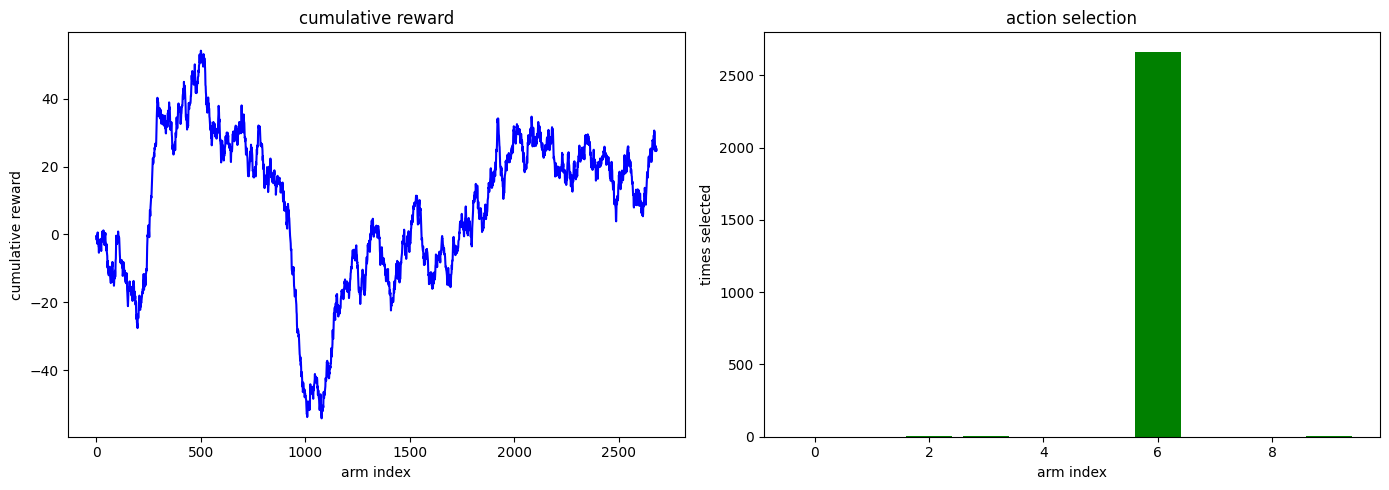

In [40]:
plt.figure(figsize =(14,5))
plt.subplot(1,2,1)
plt.plot(np.cumsum(all_rewards),color = 'blue')
plt.title("cumulative reward")
plt.xlabel("arm index")
plt.ylabel("cumulative reward")

plt.subplot(1,2,2)
plt.bar(np.arange(n_arms),counts,color = 'green')
plt.title("action selection")
plt.xlabel("arm index")
plt.ylabel("times selected")
plt.tight_layout()
plt.show()



In [27]:
import matplotlib.pyplot as plt
